Derivation rules for y = Ax + b. 
## Mean Rule: ##
$$\mu_y = \mathbb{E}[y] = \mathbb{E}[Ax + b] = A\mathbb{E}[x] + b = A\mu_x + b$$

## Covariance Rule: ## 
$$\begin{aligned}
\Sigma_y &= \mathbb{E}\left[(y - \mu_y)(y - \mu_y)^T\right] = \mathbb{E}\left[\big(A(x- \mu_x)\big)\big(A(x - \mu_x)\big)^T\right]\\
&= \mathbb{E}\left[A(x- \mu_x)(x - \mu_x)^T A^T\right] \\ 
&= A\,\mathbb{E}\left[(x -\mu_x)(x - \mu_x)^T\right]A^T = A\Sigma_x A^T
\end{aligned}$$

## First Transformation ## 
$A_1 = \begin{bmatrix} 1 & 2 \\ 0 & 1 \\ 1 & -1 \end{bmatrix}$: 
$$ \mu_{y,1} = A_1\mu_x= \begin{bmatrix} 1(1) + 2(-2) \\0(1) + 1(-2) \\ 1(1)- 1(-2) \end{bmatrix} = \begin{bmatrix} -3 \\-2 \\ 3 \end{bmatrix}$$
$$\Sigma_{y,1} = A_1\Sigma_x A_1^T = \begin{bmatrix} 8 & 10 \\ 2 & 4 \\ 2 &-2 \end{bmatrix} \begin{bmatrix} 1 & 0 &1 \\ 2 & 1 & -1\end{bmatrix} = \begin{bmatrix} 28 & 10 & -2 \\ 10 & 4 & -2\\ -2 & -2 & 4 \end{bmatrix}$$

## Rank-Deficient Transformation ## 
$A_2 = \begin{bmatrix} 1 & 1 \\ 2 & 2 \end{bmatrix}$: 
$$\mu_{y,2} = A_2 \mu_x = \begin{bmatrix} -1 \\ -2 \end{bmatrix}. \qquad \Sigma_{y,2} = A_2\Sigma_x A_2^T = \begin{bmatrix} 6 & 6 \\ 12 & 12 \end{bmatrix} \begin{bmatrix} 1 & 2 \\ 1 &2 \end{bmatrix} = \begin{bmatrix} 12 & 24 \\ 24 & 48 \end{bmatrix}$$ 

4.2: First Transformation
---------------------------
Analytical mu_y1: [-3 -2  3]
Empirical mu_y1: [-2.9989  -1.99959  2.99985]
Absolute Difference: [0.0011  0.00041 0.00015]
Standard Error: [0.00529 0.002   0.002  ]

Analytical Sigma_y1:
 [[28 10 -2]
 [10  4 -2]
 [-2 -2  4]]

Empirical Sigma:
 [[28.0162  9.9994 -1.9821]
 [ 9.9994  3.9973 -1.9924]
 [-1.9821 -1.9924  3.995 ]]

Frobenius norm || Sigma_emp - Sigma || _F = 0.03246

---------------------------
4.3 Rank & Eigenvalues
---------------------------
Rank of Sigma (3x3): 2
Eigenvalues of Sigma: [0.0, 4.14359, 31.85641]
is_valid_covariance(Sigma): True

Due to the input vector only having 2 random variables, multiplying it by a matrix 3x2 cant create another variable. For the geometry this means that samples that are in 3D are forced into a 2D space.

-----------------------------------
4.4: Rank-Deficient Transformation
-----------------------------------
Analytical mu_y2: [-1 -2]
Empirical mu_y2: [-0.99932 -1.99864]

Analytical 

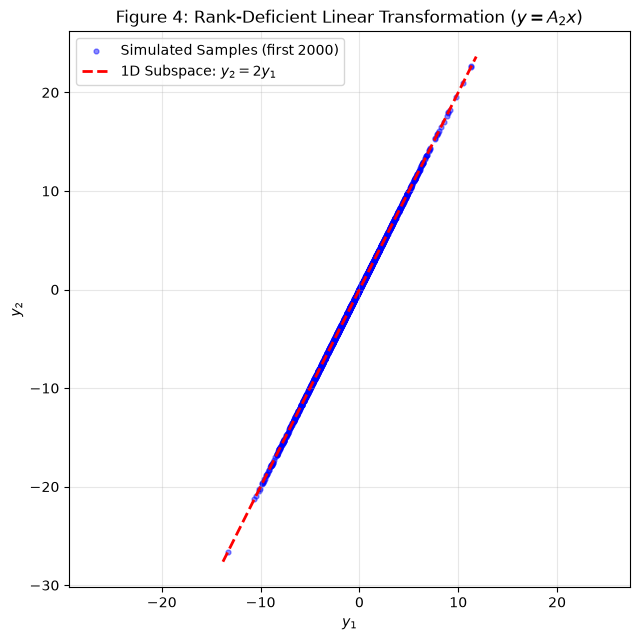

In [5]:
import numpy as np 
import matplotlib.pyplot as plt 
from mp3lib import sample_mean_cov, is_valid_covariance, gaussian_pdf

SEED = 1506714529 
rng = np.random.default_rng(SEED) 
rng_step4 = rng.spawn(1)[0]

N = 1000000
mu_x = np.array([1, -2])
Sigma_x = np.array([[4, 2], [2, 4]])

X = rng_step4.multivariate_normal(mu_x, Sigma_x, size = N)
A1 = np.array([[1, 2], [0, 1], [1, -1]])

## exact mean and covariance
mu_y1 = A1 @ mu_x
Sigma_y1 = A1 @ Sigma_x @ A1.T
Y1 = X @ A1.T 
mu_y1_emp, Sigma_y1_emp = sample_mean_cov(Y1)

## standard error from theoretical values
mu_y1_std = np.std(Y1, axis =0, ddof = 1) / np.sqrt(N)
mu_y1_diff = np.abs(mu_y1_emp - mu_y1)
Sigma_y1_frob = np.linalg.norm(Sigma_y1_emp - Sigma_y1, ord='fro') 

print("4.2: First Transformation") 
print("---------------------------")
print(f"Analytical mu_y1: {mu_y1}")
print(f"Empirical mu_y1: {np.round(mu_y1_emp,5)}")
print(f"Absolute Difference: {np.round(mu_y1_diff,5)}")
print(f"Standard Error: {np.round(mu_y1_std,5)}")
print("\nAnalytical Sigma_y1:\n", Sigma_y1)
print("\nEmpirical Sigma:\n", np.round(Sigma_y1_emp, 4))
print(f"\nFrobenius norm || Sigma_emp - Sigma || _F = {Sigma_y1_frob:.5f}")

rank_y1 = np.linalg.matrix_rank(Sigma_y1)
eigen_val = np.linalg.eigvalsh(Sigma_y1)
valid_y1 = is_valid_covariance(Sigma_y1)

print("\n---------------------------")
print("4.3 Rank & Eigenvalues") 
print("---------------------------")
print(f"Rank of Sigma (3x3): {rank_y1}")
print(f"Eigenvalues of Sigma: {[round(float(v), 5) for v in eigen_val]}")
print(f"is_valid_covariance(Sigma): {valid_y1}") 

## rank deficient transformation

A2 = np.array([[1, 1] , [2, 2]])

mu_y2 = A2 @ mu_x
Sigma_y2 = A2 @ Sigma_x @ A2.T 
Y2 = X @ A2.T
mu_y2_emp, Sigma_y2_emp = sample_mean_cov(Y2)
Sigma_y2_frob = np.linalg.norm(Sigma_y2_emp - Sigma_y2, ord='fro') 


rank_y2 = np.linalg.matrix_rank(Sigma_y2)
eigen_val = np.linalg.eigvalsh(Sigma_y2)
valid_y2 = is_valid_covariance(Sigma_y2) 


print("\nDue to the input vector only having 2 random variables, multiplying it by a matrix 3x2 cant create another variable. For the geometry this means that samples that are in 3D are forced into a 2D space.")

print("\n-----------------------------------")
print("4.4: Rank-Deficient Transformation")
print("-----------------------------------")
print(f"Analytical mu_y2: {mu_y2}")
print(f"Empirical mu_y2: {np.round(mu_y2_emp,5)}") 
print("\nAnalytical Sigma_y2:\n", Sigma_y2)
print("\nEmperical Sigma:\n", np.round(Sigma_y2_emp, 5)) 
print(f"Rank of Sigma (2x2): {rank_y2}")
print(f"Eigenvalues of Sigma: {np.round(eigen_val, 5)}")
print(f"is_valid_covariance(Sigma): {valid_y2}") 

print("\nThe second row of the matrix is double the first row meaning the second output is always twice the first coordinate. This means all the samples will lie on single 1D line.")

## part 4.5 

det_y2 = np.linalg.det(Sigma_y2)
print("\n----------------------------------------------")
print("Part 4.5 Singular Covariance Breaks Guassian PDF") 
print("----------------------------------------------") 


print(f"np.linalg.det(Sigma_y2) = {det_y2:.4e}")

## call gaussian pdf function from library 
try:
    pdf_val = gaussian_pdf(mu_y2, mu_y2, Sigma_y2)
    print(f"gaussian_pdf returned: {pdf_val}")
except (np.linalg.LinAlgError, ValueError) as err:
    print(f"gaussian_pdf failed as expected ({type(err).__name__}): {err}") 

print("\n The covariance matrix has a determinant of zero, dividing by this will cause the formula to fail.")

plt.figure(figsize=(6.5, 6.5))
n_plot = 2000
plt.scatter(Y2[:n_plot, 0], Y2[:n_plot, 1], alpha = 0.45, s=12, 
            color = "blue", label=f"Simulated Samples (first {n_plot})")

y1_grid = np.linspace(Y2[:n_plot, 0].min() - .5, Y2[:n_plot, 0].max() + 0.5, 200)
plt.plot(y1_grid, 2.0 * y1_grid, "r--", linewidth = 2, label= "1D Subspace: $y_2 = 2y_1$")

plt.title("Figure 4: Rank-Deficient Linear Transformation ($y = A_2 x$)")
plt.xlabel("$y_1$")
plt.ylabel("$y_2$")
plt.axis("equal")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

## Figure 4 Interpretation ## 
This figure confirms that the rank 1 collapse and all simulated $(y_1, y_2)$ lie along the dashed line with zero spread 